
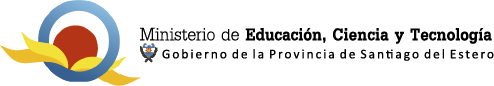

# Clase 2: Bases del Deep Learning. TP2

## Materia: Sistemas de Inteligencia Artificial

## Contenidos:

* Backpropagation





La Retropropagación (Backpropagation) es el algoritmo clave utilizado para entrenar redes neuronales, permitiéndoles aprender a partir de los datos. Se basa en la técnica de optimización de descenso por gradiente y funciona ajustando de manera iterativa los pesos y sesgos de la red para minimizar el error entre las salidas predichas y las salidas reales.
En este laboratorio, crearemos una red neuronal para implementar la retropropagación en un problema XOR.

# Objetivo del practico:

* Entrenar una Red Neuronal para resolver el problema XOR
* Implementar retropropagación (*Backpropagation*) para el entrenamiento de la Red Neuronal
* Demostrar el uso de funciones de activación
* Comprender el proceso de aprendizaje a lo largo de múltiples épocas
* Mostrar cómo se ajustan los pesos y sesgos mediante descenso por gradiente
* Evaluar el desempeño del modelo después del entrenamiento
* Monitorear y analizar el proceso de entrenamiento

<h2>Tabla de Contenidos</h2>

<div class="alert alert-block alert-info" style="margin-top: 20px">

<font size = 4>
1. <a href="#Import-Required-Libraries">Importar Bibliotecas Requeridas</a><br>
2. <a href="#Initialize-Inputs">Inicializar Entradas</a><br>
3. <a href="#Declare-the-network-parameters">Declarar los parámetros de la red</a><br>
4. <a href="#Define-the-weights">Definir los pesos</a><br>  
5. <a href="#Training-the-Neural-Network">Entrenar la Red Neuronal</a><br>  
6. <a href="#Testing-the-Network">Probar la Red</a><br>  
7. <a href="#Plot-the-error">Graficar el error</a><br>  

</font>
</div>


In [11]:
# Todas las librerías necesarias para este laboratorio se listan a continuación.
# Si ejecutas este cuaderno en un entorno diferente, por ejemplo, en tu computadora,
# puede que necesites descomentar e instalar algunas librerías.

#!pip install numpy==1.26.4
#!pip install matplotlib==3.5.2

## Importar las Librerías Requeridas


In [12]:
# Importando la librería requerida

import numpy as np
import matplotlib.pyplot as plt

## Inicializar Entradas
Definir la entrada y la salida esperada para un problema de puerta XOR


In [13]:
# Definir las entradas y la salida esperada (tabla de verdad XOR)
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]]).T  # Matriz 2x4, cada columna es un ejemplo de entrenamiento
d = np.array([0, 1, 1, 0])  # Salida esperada para XOR


# Declarar los parámetros de la red y los pesos

Define los parámetros de la red, tales como:  
1. Número de neuronas de entrada  
2. Neuronas de la capa oculta  
3. Neuronas de salida  
4. Tasa de aprendizaje  
5. Número de épocas  

Además, declara los pesos de las neuronas. Los pesos iniciales se toman como números aleatorios, los cuales luego se optimizan mediante el algoritmo de retropropagación dentro de una función llamada `initialize_network_parameters()`.


In [14]:
def initialize_network_parameters():
    # Parámetros de la red
    inputSize = 2      # Número de neuronas de entrada (x1, x2)
    hiddenSize = 2     # Número de neuronas en la capa oculta
    outputSize = 1     # Número de neuronas de salida
    lr = 0.1           # Tasa de aprendizaje
    epochs = 100000    # Número de épocas de entrenamiento

    # Inicializar pesos y sesgos aleatoriamente en el rango [-1, 1]
    w1 = np.random.rand(hiddenSize, inputSize) * 2 - 1  # Pesos de la capa de entrada a la oculta
    b1 = np.random.rand(hiddenSize, 1) * 2 - 1          # Sesgo para la capa oculta
    w2 = np.random.rand(outputSize, hiddenSize) * 2 - 1 # Pesos de la capa oculta a la de salida
    b2 = np.random.rand(outputSize, 1) * 2 - 1          # Sesgo para la capa de salida

    return w1, b1, w2, b2, lr, epochs


**Explicación de la función `initialize_network_parameters()`:**

Esta función configura la arquitectura básica de la red neuronal. Crea 4 matrices de pesos y sesgos (w1, b1, w2, b2) con valores aleatorios entre -1 y 1.

- **w1** conecta la capa de entrada (2 neuronas) con la capa oculta (2 neuronas): dimensión (2,2)
- **b1** es el sesgo de la capa oculta: dimensión (2,1)
- **w2** conecta la capa oculta (2 neuronas) con la capa de salida (1 neurona): dimensión (1,2)
- **b2** es el sesgo de la capa de salida: dimensión (1,1)
- **lr=0.1** controla qué tan rápido se ajustan los pesos en cada iteración
- **epochs=100000** define cuántas veces se repetirá el proceso de entrenamiento

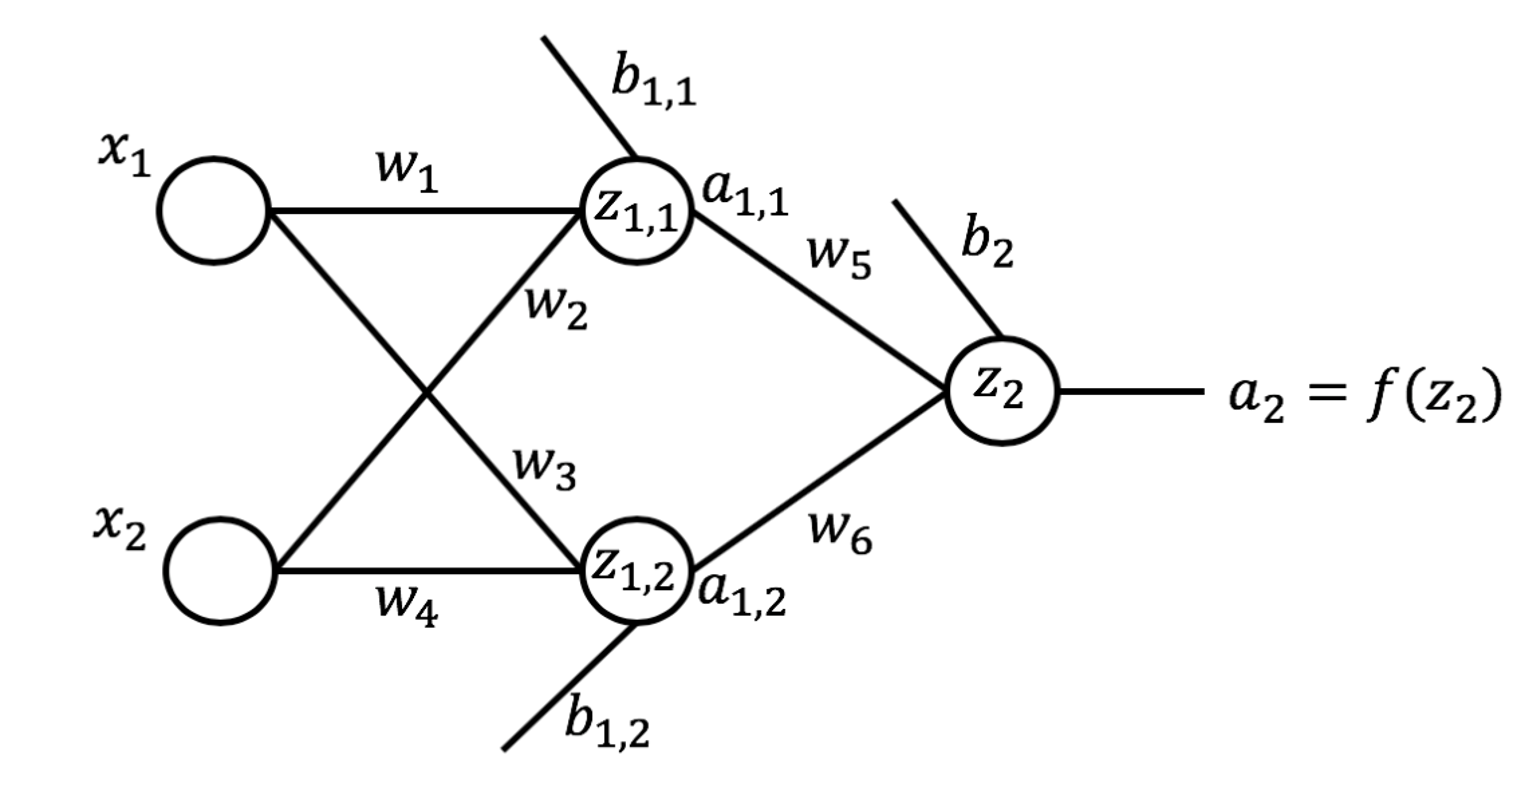

## Entrenamiento de la Red Neuronal

La red neuronal funciona en 5 etapas:  

1. **Propagación hacia adelante (Forward pass)**
    * La entrada **X** se multiplica por los pesos **w1** y se pasa a través de la primera capa, seguida de la aplicación de la función de activación sigmoide o ReLU. Esto genera la salida de la capa oculta.  
    * La salida de la capa oculta se pasa luego a través del segundo conjunto de pesos **w2** para calcular la salida final. Nuevamente, se utiliza la función de activación sigmoide para generar la salida final **a2**.  

2. **Cálculo del error**
    * El error se calcula como la diferencia entre la salida esperada **(d)** y la salida real **(a2)**.  

3. **Propagación hacia atrás (Backward pass)**
    * **Capa de salida**: Se aplica la derivada de la función de activación sigmoide al error, produciendo el gradiente para la capa de salida **(da2)**. Esto se utiliza para calcular cuánto deben ajustarse los pesos en la capa de salida.  
    * **Capa oculta**: El error se propaga hacia atrás hasta la capa oculta. El gradiente en la capa oculta **(da1)** se calcula tomando el producto punto de la transpuesta de los pesos **(w2.T)** y el gradiente de la capa de salida. Se utiliza la derivada de la función de activación (sigmoide o ReLU) para ajustar este error.  

4. **Actualización de pesos y sesgos**
    * Después de calcular los **gradientes (dz1, dz2)**, los **pesos (w1, w2)** y **sesgos (b1, b2)** se actualizan utilizando la **tasa de aprendizaje (lr)** y los **gradientes**. Las actualizaciones se realizan para minimizar el error y mejorar las predicciones del modelo.  

5. **Entrenamiento**
    * Este proceso completo se repite durante muchas iteraciones **(épocas)**. Durante cada época, el modelo ajusta sus pesos y sesgos para reducir el error. Con el tiempo, la red aprende a aproximar la función XOR.  

**Propagación hacia adelante (Forward Pass):**


In [15]:
# Obtener los parámetros inicializados
w1, b1, w2, b2, lr, epochs = initialize_network_parameters()
print(w1, b1, w2, b2, lr, epochs, "pesos, bias y epocas")
print(X, "entradas")
# Entrenar la red usando retropropagación

lista_errores = []
lista_epocas = []
for epoch in range(epochs):
    # Propagación hacia adelante
    z1 = np.dot(w1, X) + b1  # Suma ponderada para la capa oculta

    a1 = 1 / (1 + np.exp(-z1))  # Activación sigmoide para la capa oculta

    z2 = np.dot(w2, a1) + b2  # Suma ponderada para la capa de salida
    a2 = 1 / (1 + np.exp(-z2))  # Activación sigmoide para la capa de salida

    # Cálculo del error y retropropagación
    error = d - a2  # Diferencia entre la salida esperada y la obtenida
    da2 = error * (a2 * (1 - a2))  # Derivada para la capa de salida (derivada de la función sigmoide)
    dz2 = da2  # Gradiente para la capa de salida

    # Propagar el error a la capa oculta
    da1 = np.dot(w2.T, dz2)  # Gradiente para la capa oculta (responsabilidad de la capa oculta en el error)
    dz1 = da1 * (a1 * (1 - a1))  # Derivada para la capa oculta

    # Actualizar pesos y sesgos
    w2 += lr * np.dot(dz2, a1.T)  # Actualizar pesos de la capa oculta a la de salida
    b2 += lr * np.sum(dz2, axis=1, keepdims=True)  # Actualizar sesgo de la capa de salida

    w1 += lr * np.dot(dz1, X.T)  # Actualizar pesos de la capa de entrada a la oculta
    b1 += lr * np.sum(dz1, axis=1, keepdims=True)  # Actualizar sesgo de la capa oculta

    if (epoch + 1) % 100 == 0:
      error_promedio = np.average(abs(error))

      print("Ã‰poca: %d, Error promedio: %0.05f" %
            (epoch + 1, error_promedio))

      lista_errores.append(error_promedio)
      lista_epocas.append(epoch + 1)


[[-0.69661206  0.94994413]
 [-0.49924196 -0.74970377]] [[-0.04697227]
 [ 0.89126872]] [[0.86626872 0.50627811]] [[0.41531613]] 0.1 100000 pesos, bias y epocas
[[0 0 1 1]
 [0 1 0 1]] entradas
Ã‰poca: 100, Error promedio: 0.49955
Ã‰poca: 200, Error promedio: 0.49938
Ã‰poca: 300, Error promedio: 0.49921
Ã‰poca: 400, Error promedio: 0.49902
Ã‰poca: 500, Error promedio: 0.49881
Ã‰poca: 600, Error promedio: 0.49857
Ã‰poca: 700, Error promedio: 0.49828
Ã‰poca: 800, Error promedio: 0.49794
Ã‰poca: 900, Error promedio: 0.49752
Ã‰poca: 1000, Error promedio: 0.49701
Ã‰poca: 1100, Error promedio: 0.49636
Ã‰poca: 1200, Error promedio: 0.49555
Ã‰poca: 1300, Error promedio: 0.49452
Ã‰poca: 1400, Error promedio: 0.49321
Ã‰poca: 1500, Error promedio: 0.49154
Ã‰poca: 1600, Error promedio: 0.48941
Ã‰poca: 1700, Error promedio: 0.48672
Ã‰poca: 1800, Error promedio: 0.48336
Ã‰poca: 1900, Error promedio: 0.47924
Ã‰poca: 2000, Error promedio: 0.47432
Ã‰poca: 2100, Error promedio: 0.46861
Ã‰poca: 2200, Error 

**Explicación del proceso de entrenamiento (Retropropagación):**

El bucle principal ejecuta 100,000 iteraciones (épocas) donde en cada una:

1. **Forward Pass (Propagación hacia adelante):**
   - z1 = w1·X + b1: Calcula la suma ponderada de entrada a la capa oculta
   - a1 = sigmoid(z1): Aplica función de activación sigmoide (mapea valores a rango 0-1)
   - z2 = w2·a1 + b2: Calcula la suma ponderada de la capa oculta a la salida
   - a2 = sigmoid(z2): Genera la predicción final de la red

2. **Cálculo del error:**
   - error = d - a2: Mide qué tan lejos está la predicción del valor esperado

3. **Backward Pass (Retropropagación):**
   - da2 = error · sigmoid'(a2): Calcula el gradiente del error en la capa de salida
   - da1 = w2.T · da2: Propaga el error hacia atrás a la capa oculta
   - dz1 = da1 · sigmoid'(a1): Calcula el gradiente en la capa oculta

4. **Actualización de pesos:**
   - w2 += lr · dz2·a1.T: Ajusta pesos de capa oculta a salida
   - b2 += lr · sum(dz2): Ajusta sesgo de salida
   - w1 += lr · dz1·X.T: Ajusta pesos de entrada a capa oculta
   - b1 += lr · sum(dz1): Ajusta sesgo de capa oculta

5. **Monitoreo:**
   - Cada 100 épocas se imprime y guarda el error promedio para graficar después
   - El error promedio debe disminuir con el tiempo, indicando que la red aprende

In [16]:
print(w1)

z1

[[-6.58169394  6.56869326]
 [ 5.86048495 -6.14371842]]


array([[ -3.6714027 ,   2.89728786, -10.25309351,  -3.68440295],
       [ -3.2283656 ,  -9.37208028,   2.63211547,  -3.51159922]])

## Probando la Red
Después del entrenamiento, ahora puedes probar la red neuronal para verificar que ha aprendido la función XOR y produce los valores correctos, cercanos a [0, 1, 1, 0].


In [17]:
# Probar la red entrenada
z1 = np.dot(w1, X) + b1  # Suma ponderada para la capa oculta
a1 = 1 / (1 + np.exp(-z1))  # Activación sigmoide para la capa oculta

z2 = np.dot(w2, a1) + b2  # Suma ponderada para la capa de salida
a2 = 1 / (1 + np.exp(-z2))  # Activación sigmoide para la capa de salida

# Imprimir resultados
print('Salida final después del entrenamiento:', a2)
print('Valor real (ground truth):', d)
print('Error después del entrenamiento:', error)
print('Error promedio: %0.05f' % np.average(abs(error)))


Salida final después del entrenamiento: [[0.01264445 0.98910928 0.98899529 0.01150018]]
Valor real (ground truth): [0 1 1 0]
Error después del entrenamiento: [[-0.01264452  0.01089078  0.01100477 -0.01150025]]
Error promedio: 0.01151


**Explicación de la prueba de la red:**

Después del entrenamiento, se realiza una última propagación hacia adelante usando los pesos ya optimizados para verificar que la red aprendió correctamente.

Se imprime:
- **Salida final (a2):** Debe ser cercana a [0, 1, 1, 0] (tabla XOR)
- **Valor real (d):** Los valores esperados [0, 1, 1, 0]
- **Error:** La diferencia entre predicción y valor real (debe ser muy pequeño)
- **Error promedio:** Un solo número que resume qué tan bien aprendió la red

Si el error promedio es menor a 0.05, la red aprendió exitosamente XOR que es un problema NO linealmente separable (no se puede resolver con una sola neurona).

## Graficar el error
Aquí, graficamos el error en función de las épocas. Esto muestra cómo cambió el error a lo largo de múltiples iteraciones de propagación hacia adelante y hacia atrás, y cómo la red fue aprendiendo con el tiempo.


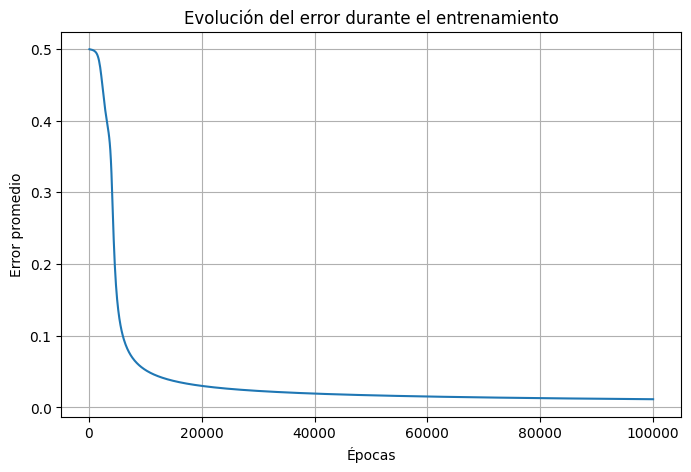

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(lista_epocas, lista_errores)

plt.title('Evolución del error durante el entrenamiento')
plt.xlabel('Ã‰pocas')
plt.ylabel('Error promedio')
plt.grid(True)

plt.show()

**Explicación del gráfico de error:**

Este gráfico visualiza la curva de aprendizaje de la red neuronal.

- **Eje X (Ã‰pocas):** Muestra las iteraciones de entrenamiento (cada 100 épocas)
- **Eje Y (Error promedio):** Muestra qué tan equivocada está la red

Interpretación del gráfico:
- Al inicio (época 0): El error es alto (~0.5) porque los pesos son aleatorios
- Durante el entrenamiento: La curva desciende indicando que la red está aprendiendo
- Al final: El error se estabiliza en un valor bajo (cerca de 0)

Una buena curva de aprendizaje muestra:
1. Descenso rápido al principio
2. Gradualmente se aplana cuando la red converge
3. Se estabiliza en un valor bajo (sin oscilaciones grandes)

# Ejercicio Practico 1:


Implementar la retropropagación para el **problema AND** usando entradas similares a las utilizadas para el problema XOR mencionado anteriormente y graficar el error.



In [19]:
# Actividad 1: Retropropagación para el problema AND

# Definir las entradas y la salida esperada (tabla de verdad AND)
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]]).T  # Matriz 2x4
d = np.array([0, 0, 0, 1])  # Salida esperada para AND

# Obtener los parámetros inicializados
w1, b1, w2, b2, lr, epochs = initialize_network_parameters()

# Entrenar la red usando retropropagación
lista_errores_and = []
lista_epocas_and = []
for epoch in range(epochs):
    # Propagación hacia adelante
    z1 = np.dot(w1, X) + b1
    a1 = 1 / (1 + np.exp(-z1))

    z2 = np.dot(w2, a1) + b2
    a2 = 1 / (1 + np.exp(-z2))

    # Cálculo del error y retropropagación
    error = d - a2
    da2 = error * (a2 * (1 - a2))
    dz2 = da2

    da1 = np.dot(w2.T, dz2)
    dz1 = da1 * (a1 * (1 - a1))

    # Actualizar pesos y sesgos
    w2 += lr * np.dot(dz2, a1.T)
    b2 += lr * np.sum(dz2, axis=1, keepdims=True)
    w1 += lr * np.dot(dz1, X.T)
    b1 += lr * np.sum(dz1, axis=1, keepdims=True)

    if (epoch + 1) % 100 == 0:
        error_promedio = np.average(abs(error))
        lista_errores_and.append(error_promedio)
        lista_epocas_and.append(epoch + 1)

# Probar la red entrenada
z1 = np.dot(w1, X) + b1
a1 = 1 / (1 + np.exp(-z1))
z2 = np.dot(w2, a1) + b2
a2 = 1 / (1 + np.exp(-z2))

# Imprimir resultados
print('Salida final después del entrenamiento (AND):', a2)
print('Valor real (ground truth):', d)
print('Error después del entrenamiento:', error)
print('Error promedio: %0.05f' % np.average(abs(error)))

# Graficar el error
plt.figure(figsize=(8, 5))
plt.plot(lista_epocas_and, lista_errores_and)
plt.title('Evolución del error durante el entrenamiento (AND)')
plt.xlabel('Ã‰pocas')
plt.ylabel('Error promedio')
plt.grid(True)
plt.show()

**Explicación de la Actividad 1 - Problema AND:**

Este código implementa la misma red neuronal pero para la puerta AND.

**Diferencias con XOR:**
- AND solo retorna 1 cuando AMBAS entradas son 1: [0,0,0,1]
- XOR retorna 1 cuando las entradas son DIFERENTES: [0,1,1,0]

AND es linealmente separable (se puede resolver con una sola neurona). XOR NO es linealmente separable (necesita una capa oculta).

El código realiza:
1. Define la tabla de verdad AND: d = [0, 0, 0, 1]
2. Inicializa la red con la misma función (2-2-1 neuronas)
3. Entrena con backpropagation durante 100,000 épocas
4. Prueba la red y muestra que el error es muy bajo
5. Grafica la curva de aprendizaje (debe converger más rápido que XOR)

El error de AND debería ser menor que XOR porque es un problema más simple.

Haz doble clic <b>aquí</b> para ver la solución.

<!-- Tu respuesta está abajo:

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]]).T  # Matriz 2x4, cada columna es un ejemplo de entrenamiento
d = np.array([0, 0, 0, 1])  # Salida esperada para AND

# Obtener los parámetros inicializados
w1, b1, w2, b2, lr, epochs = initialize_network_parameters()

# Entrenando la red usando retropropagación
error_list = []
for epoch in range(epochs):
    # Propagación hacia adelante
    z1 = np.dot(w1, X) + b1  # Suma ponderada para la capa oculta
    a1 = 1 / (1 + np.exp(-z1))  # Activación sigmoide para la capa oculta

    z2 = np.dot(w2, a1) + b2  # Suma ponderada para la capa de salida
    a2 = 1 / (1 + np.exp(-z2))  # Activación sigmoide para la capa de salida

    # Cálculo del error y retropropagación
    error = d - a2  # Diferencia entre la salida esperada y la real
    da2 = error * (a2 * (1 - a2))  # Derivada para la capa de salida
    dz2 = da2  # Gradiente para la capa de salida

    # Propagar el error a la capa oculta
    da1 = np.dot(w2.T, dz2)  # Gradiente para la capa oculta
    dz1 = da1 * (a1 * (1 - a1))  # Derivada para la capa oculta

    # Actualizar pesos y sesgos
    w2 += lr * np.dot(dz2, a1.T)  # Actualizar pesos de la capa oculta a la de salida
    b2 += lr * np.sum(dz2, axis=1, keepdims=True)  # Actualizar sesgo de la capa de salida

    w1 += lr * np.dot(dz1, X.T)  # Actualizar pesos de la capa de entrada a la oculta
    b1 += lr * np.sum(dz1, axis=1, keepdims=True)  # Actualizar sesgo de la capa oculta
    if (epoch+1)%10000 == 0:
        print("Ã‰poca: %d, Error promedio: %0.05f"%(epoch, np.average(abs(error))))
        error_list.append(np.average(abs(error)))

# Probar la red entrenada
z1 = np.dot(w1, X) + b1  # Suma ponderada para la capa oculta
a1 = 1 / (1 + np.exp(-z1))  # Activación sigmoide para la capa oculta

z2 = np.dot(w2, a1) + b2  # Suma ponderada para la capa de salida
a2 = 1 / (1 + np.exp(-z2))  # Activación sigmoide para la capa de salida

# Imprimir resultados
print('\nSalida final después del entrenamiento:', a2)
print('Valor real', d)
print('Error después del entrenamiento:', error)
print('Error promedio: %0.05f'%np.average(abs(error)))

# Graficar error
plt.plot(error_list)
plt.title('Error')
plt.xlabel('Ã‰pocas')
plt.ylabel('Error')
plt.show()

-->


# Ejercicio Practico 2:


Ahora, disminuye la tasa de aprendizaje a 0.01 y aumenta el número de épocas a 1,000,000, y verifica el error para la compuerta XOR.


In [20]:
# Actividad 2: XOR con lr=0.01 y epochs=1,000,000

# Definir parámetros modificados
lr = 0.01           # Tasa de aprendizaje reducida
epochs = 1000000    # Número de épocas aumentado

# Definir entradas y salida esperada (tabla de verdad XOR)
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]]).T  # Matriz 2x4
d = np.array([0, 1, 1, 0])  # Salida esperada para XOR

# Inicializar pesos y sesgos aleatoriamente
w1 = np.random.rand(2, 2) * 2 - 1  # Pesos de entrada a capa oculta
b1 = np.random.rand(2, 1) * 2 - 1  # Sesgo capa oculta
w2 = np.random.rand(1, 2) * 2 - 1  # Pesos de capa oculta a salida
b2 = np.random.rand(1, 1) * 2 - 1  # Sesgo capa de salida

# Entrenar la red usando retropropagación
lista_errores_xor2 = []
lista_epocas_xor2 = []
for epoch in range(epochs):
    # Propagación hacia adelante
    z1 = np.dot(w1, X) + b1
    a1 = 1 / (1 + np.exp(-z1))

    z2 = np.dot(w2, a1) + b2
    a2 = 1 / (1 + np.exp(-z2))

    # Cálculo del error y retropropagación
    error = d - a2
    da2 = error * (a2 * (1 - a2))
    dz2 = da2

    da1 = np.dot(w2.T, dz2)
    dz1 = da1 * (a1 * (1 - a1))

    # Actualizar pesos y sesgos
    w2 += lr * np.dot(dz2, a1.T)
    b2 += lr * np.sum(dz2, axis=1, keepdims=True)
    w1 += lr * np.dot(dz1, X.T)
    b1 += lr * np.sum(dz1, axis=1, keepdims=True)

    if (epoch + 1) % 10000 == 0:
        error_promedio = np.average(abs(error))
        print("Ã‰poca: %d, Error promedio: %0.05f" % (epoch + 1, error_promedio))
        lista_errores_xor2.append(error_promedio)
        lista_epocas_xor2.append(epoch + 1)

# Probar la red entrenada
z1 = np.dot(w1, X) + b1
a1 = 1 / (1 + np.exp(-z1))
z2 = np.dot(w2, a1) + b2
a2 = 1 / (1 + np.exp(-z2))

# Imprimir resultados
print('\nSalida final después del entrenamiento (XOR lr=0.01):', a2)
print('Valor real (ground truth):', d)
print('Error después del entrenamiento:', error)
print('Error promedio: %0.05f' % np.average(abs(error)))

# Graficar el error
plt.figure(figsize=(8, 5))
plt.plot(lista_epocas_xor2, lista_errores_xor2)
plt.title('Evolución del error - XOR (lr=0.01, epochs=1,000,000)')
plt.xlabel('Ã‰pocas')
plt.ylabel('Error promedio')
plt.grid(True)
plt.show()

**Explicación de la Actividad 2 - XOR con parámetros modificados:**

Este código prueba cómo afecta un learning rate más pequeño al entrenamiento.

**Cambios respecto al ejemplo original:**
- lr = 0.01 (antes era 0.1): 10 veces más lento el aprendizaje
- epochs = 1,000,000 (antes era 100,000): 10 veces más iteraciones

**Efecto esperado:**
- Con lr más pequeño, cada ajuste de peso es más sutil
- Se necesitan más épocas para converger
- El error promedio debería ser MÁS BAJO que con lr=0.1
- La curva de aprendizaje será más suave pero más lenta

**Comparación:**
- XOR con lr=0.1: Error promedio ~0.0115 después de 100,000 épocas
- XOR con lr=0.01: Error promedio debería ser menor, pero tarda más

Esto demuestra el trade-off entre velocidad de convergencia y precisión.

Haz doble clic <b>aquí</b> para ver la solución.

<!-- Tu respuesta está abajo:

lr = 0.01         # Tasa de aprendizaje
epochs = 1000000   # Número de épocas de entrenamiento

# Definir entradas y salida esperada (tabla de verdad XOR)
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]]).T  # Matriz 2x4, cada columna es un ejemplo de entrenamiento
d = np.array([0, 1, 1, 0])  # Salida esperada para XOR

# Obtener parámetros inicializados
w1, b1, w2, b2, lr, epochs = initialize_network_parameters()

# Entrenar la red usando retropropagación
error_list = []
for epoch in range(epochs):
    # Propagación hacia adelante
    z1 = np.dot(w1, X) + b1  # Suma ponderada para la capa oculta
    a1 = 1 / (1 + np.exp(-z1))  # Activación sigmoide para la capa oculta

    z2 = np.dot(w2, a1) + b2  # Suma ponderada para la capa de salida
    a2 = 1 / (1 + np.exp(-z2))  # Activación sigmoide para la capa de salida

    # Cálculo del error y retropropagación
    error = d - a2  # Diferencia entre salida esperada y salida real
    da2 = error * (a2 * (1 - a2))  # Derivada para la capa de salida
    dz2 = da2  # Gradiente para la capa de salida

    # Propagar el error a la capa oculta
    da1 = np.dot(w2.T, dz2)  # Gradiente para la capa oculta
    dz1 = da1 * (a1 * (1 - a1))  # Derivada para la capa oculta

    # Actualizar pesos y sesgos
    w2 += lr * np.dot(dz2, a1.T)  # Actualizar pesos de la capa oculta a la capa de salida
    b2 += lr * np.sum(dz2, axis=1, keepdims=True)  # Actualizar sesgo de la capa de salida

    w1 += lr * np.dot(dz1, X.T)  # Actualizar pesos de la entrada a la capa oculta
    b1 += lr * np.sum(dz1, axis=1, keepdims=True)  # Actualizar sesgo de la capa oculta
    
    if (epoch+1)%10000 == 0:
        print("Ã‰poca: %d, Error promedio: %0.05f"%(epoch, np.average(abs(error))))
        error_list.append(np.average(abs(error)))

# Probar la red entrenada
z1 = np.dot(w1, X) + b1  # Suma ponderada para la capa oculta
a1 = 1 / (1 + np.exp(-z1))  # Activación sigmoide para la capa oculta

z2 = np.dot(w2, a1) + b2  # Suma ponderada para la capa de salida
a2 = 1 / (1 + np.exp(-z2))  # Activación sigmoide para la capa de salida

# Imprimir resultados
print('\nSalida final después del entrenamiento:', a2)
print('Valor real', d)
print('Error después del entrenamiento:', error)
print('Error promedio: %0.05f'%np.average(abs(error)))

# Graficar error
plt.plot(error_list)
plt.title('Error')
plt.xlabel('Ã‰pocas')
plt.ylabel('Error')
plt.show()

-->


## Felicitaciones! completaste el practico!
